# Studio risultati: FedHydra vs Fed2RC 

Ordine logico: **carico → rimuovo i duplicati → controllo la copertura dei dataset → confronto solo su dataset comuni**.
k = kernel
g = gruppi
r = round (1 equivale a -r 0)

## 1. 

In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

file_dict = {
    'miniRocket_84k': '../minifed2rc_results_1s_84k.csv',
    'miniRocket_924k': '../minifed2rc_results_1s_924k.csv',
    'Rocket_512k_1r':  '../fed2rc_wvc_results_1s_512k_1r.csv',
    'Rocket_512k':     '../fed2rc_wvc_results_1s_512k.csv',
    'Rocket_4096k_1r':  '../fed2rc_wvc_results_1s_4096k_1r.csv',
    'Rocket_4096k':     '../fed2rc_wvc_results_1s_4096k.csv',
    'Rocket_base_512k':     '../fed2rc_results_1s_512k.csv',
    'Rocket_base_512k_1r':     '../fed2rc_results_1s_512k_1r.csv',
    'Hydra_8k_64g_1r': '../fedhydra_results_1s_8k_64g_1r.csv',
    'Hydra_8k_64g':    '../fedhydra_results_1s_8k_64g.csv',
}

EXCLUDE_MODELS = []

N_HYDRA_TOP = 2

METRICS = ['Test_Accuracy', 'Test_F1', 'Rounds_to_Converge']

frames = []
for model, path in file_dict.items():
    if model in EXCLUDE_MODELS:
        continue
    try:
        d = pd.read_csv(path)
    except FileNotFoundError:
        print(f'File non trovato: {path}')
        continue
    d['Model'] = model
    d['Family'] = 'Rocket' if model.startswith('Rocket') or model.startswith('miniRocket') else 'Hydra'
    frames.append(d)

raw = pd.concat(frames, ignore_index=True)
if 'Seed' not in raw.columns:
    raw['Seed'] = -1
raw['Seed'] = raw['Seed'].fillna(-1)

print(f'Righe caricate: {len(raw)}  |  Modelli: {raw.Model.nunique()}  |  Dataset: {raw.Dataset.nunique()}')

Righe caricate: 53  |  Modelli: 10  |  Dataset: 5


## 2. Duplicati

`fedhydra.py` scrive il CSV in modalità append (`mode='a'`): **ogni rilancio aggiunge righe** invece di sostituirle.
Se non si eliminano, la stessa configurazione conta più volte nelle medie e può comparire più volte nelle classifiche.
Tengo l'**ultima** riga per ogni (Modello, Dataset, Seed), cioè l'ultima run eseguita.

In [27]:
key = ['Model', 'Dataset', 'Seed']

dup = raw.groupby(key).size().rename('n_righe').reset_index()
dup = dup[dup.n_righe > 1]
print(f'Combinazioni (Modello, Dataset, Seed) duplicate: {len(dup)}')

if len(dup):
    chk = raw.merge(dup[key], on=key)
    display(chk.sort_values(key)[key + METRICS])

df = raw.drop_duplicates(subset=key, keep='last').copy()
print(f'Righe dopo la deduplicazione: {len(df)} (rimosse {len(raw) - len(df)})')

# un solo valore per (Modello, Dataset): media sui seed
per_ds = (df.groupby(['Family', 'Model', 'Dataset'], as_index=False)[METRICS].mean())

Combinazioni (Modello, Dataset, Seed) duplicate: 0
Righe dopo la deduplicazione: 53 (rimosse 0)


## 3. Controllo se ci sono tutti i ds

Una media calcolata su dataset diversi **non è confrontabile**: un modello senza i dataset difficili
sembra migliore solo perché non è stato testato lì. Le celle vuote (`NaN`) qui sotto sono i buchi.

In [28]:
acc_pivot = per_ds.pivot(index='Dataset', columns='Model', values='Test_Accuracy')
display(acc_pivot)

all_datasets = set(per_ds.Dataset)
missing = {m: sorted(all_datasets - set(g.Dataset)) for m, g in per_ds.groupby('Model')}
missing = {m: v for m, v in missing.items() if v}

if missing:
    print('\nModelli con dataset mancanti (limitano il confronto):')
    for m, v in missing.items():
        print(f'  {m}: mancano {v}')
else:
    print('\nTutti i modelli hanno tutti i dataset.')

common_datasets = sorted(set.intersection(*[set(g.Dataset) for _, g in per_ds.groupby('Model')]))
print(f'\nDataset presenti in TUTTI i modelli ({len(common_datasets)}): {common_datasets}')

Model,Hydra_8k_64g,Hydra_8k_64g_1r,Rocket_4096k,Rocket_4096k_1r,Rocket_512k,Rocket_512k_1r,Rocket_base_512k,Rocket_base_512k_1r,miniRocket_84k,miniRocket_924k
Dataset,,,,,,,,,,
Adiac,0.7647,0.7852,0.7826,0.7954,0.7340,0.7494,0.7570,0.7647,0.6803,0.7954
Car,0.9167,0.9167,0.9000,0.9167,0.8833,0.9000,0.8708,0.8833,0.7500,0.9000
Coffee,1.0000,1.0000,0.9643,1.0000,0.9286,1.0000,0.4643,0.7143,0.9286,0.9286
Computers,0.7240,0.7160,0.7880,0.7720,0.7400,0.7760,0.5000,0.5040,0.7000,0.6720
EOGHorizontalSignal,0.6022,0.6133,0.5359,0.5552,0.5552,0.5663,0.5746,0.5718,0.3122,0.5801



Tutti i modelli hanno tutti i dataset.

Dataset presenti in TUTTI i modelli (5): ['Adiac', 'Car', 'Coffee', 'Computers', 'EOGHorizontalSignal']


## 6. Top 3 per ogni dataset 

In [29]:
for ds in sorted(per_ds.Dataset.unique()):
    top = (per_ds[per_ds.Dataset == ds]
           .sort_values(['Test_Accuracy', 'Test_F1'], ascending=False)
           .head(3))
    print(f"\n{'=' * 50}\n{ds.upper()}\n{'=' * 50}")
    print(top[['Model', 'Test_Accuracy', 'Test_F1', 'Rounds_to_Converge']].to_string(index=False))


ADIAC
          Model  Test_Accuracy  Test_F1  Rounds_to_Converge
Rocket_4096k_1r         0.7954   0.7674              0.0000
miniRocket_924k         0.7954   0.7632              1.0000
Hydra_8k_64g_1r         0.7852   0.7683              0.0000

CAR
          Model  Test_Accuracy  Test_F1  Rounds_to_Converge
   Hydra_8k_64g         0.9167   0.9179              2.0000
Hydra_8k_64g_1r         0.9167   0.9179              0.0000
Rocket_4096k_1r         0.9167   0.9151              0.0000

COFFEE
          Model  Test_Accuracy  Test_F1  Rounds_to_Converge
   Hydra_8k_64g         1.0000   1.0000              2.0000
Hydra_8k_64g_1r         1.0000   1.0000              0.0000
Rocket_4096k_1r         1.0000   1.0000              0.0000

COMPUTERS
          Model  Test_Accuracy  Test_F1  Rounds_to_Converge
   Rocket_4096k         0.7880   0.7985              2.0000
 Rocket_512k_1r         0.7760   0.7863              0.0000
Rocket_4096k_1r         0.7720   0.7765              0.0000

EOGHORIZ

In [30]:
time_mapping = {
    'Hydra_8k_64g': 234.5,
    'Hydra_8k_64g_1r': 711.4,
    'Rocket_512k': 64.7,
    'Rocket_512k_1r': 76.9,
    'Rocket_4096k': 662.7,
    'Rocket_4096k_1r': 2575.2,
    'Rocket_base_512k': 77.2,
    'Rocket_base_512k_1r': 55.1,
    'miniRocket_84k': 2.6,
    'miniRocket_924k': 34.5
}

def summarize(models, datasets):
    sub = per_ds[per_ds.Model.isin(models) & per_ds.Dataset.isin(datasets)].copy()
    sub['Rank'] = sub.groupby('Dataset')['Test_Accuracy'].rank(ascending=False, method='average')
    
    out = (sub.groupby(['Family', 'Model'])
              .agg(Avg_Rank=('Rank', 'mean'),
                   N_datasets=('Dataset', 'nunique'))
              .reset_index())
    
    out['Time_s'] = out['Model'].map(time_mapping)
    
    return out.sort_values('Avg_Rank', ascending=True).reset_index(drop=True)

all_models = sorted(per_ds.Model.unique())

In [31]:
ranking = summarize(all_models, common_datasets)
display(ranking)

,Family,Model,Avg_Rank,N_datasets,Time_s
0,Hydra,Hydra_8k_64g_1r,2.9000,5,711.4000
1,Rocket,Rocket_4096k_1r,3.3000,5,2575.2000
2,Hydra,Hydra_8k_64g,3.4000,5,234.5000
3,Rocket,Rocket_512k_1r,4.7000,5,76.9000
4,Rocket,Rocket_4096k,4.8000,5,662.7000
5,Rocket,miniRocket_924k,4.9000,5,34.5000
6,Rocket,Rocket_512k,7.0000,5,64.7000
7,Rocket,Rocket_base_512k_1r,7.2000,5,55.1000
8,Rocket,Rocket_base_512k,8.0000,5,77.2000
9,Rocket,miniRocket_84k,8.8000,5,2.6000


## 7. Heatmap accuratezza (modelli × dataset)

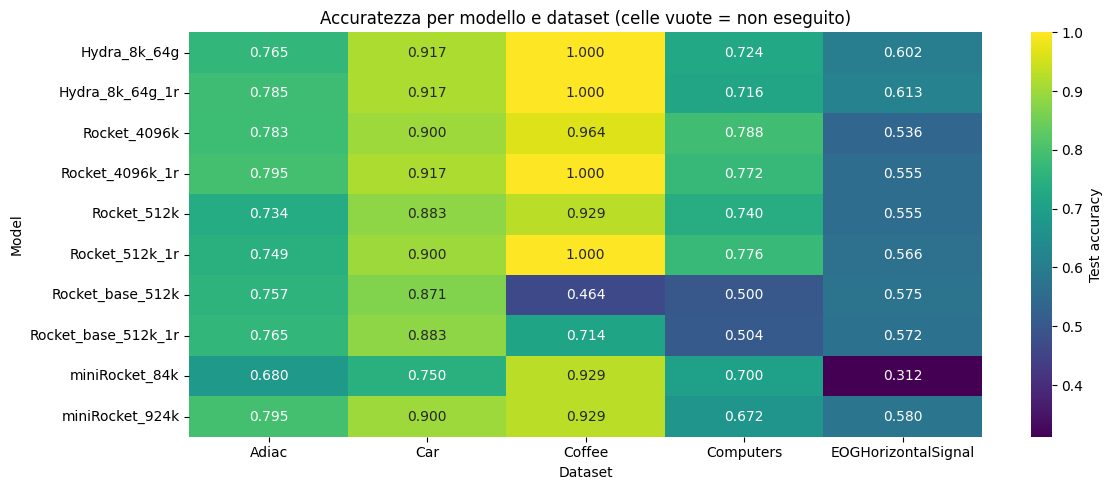

In [32]:
plt.figure(figsize=(1.0 * len(all_models) + 2, 0.6 * len(acc_pivot) + 2))
sns.heatmap(acc_pivot.T, annot=True, fmt='.3f', cmap='viridis', cbar_kws={'label': 'Test accuracy'})
plt.title('Accuratezza per modello e dataset (celle vuote = non eseguito)')
plt.tight_layout()
plt.show()

## 8. Confronto finale: migliori Hydra vs Rocket

I migliori Hydra sono scelti con la classifica della sezione 5.

In [33]:
top_hydra = ranking[ranking.Family == 'Hydra'].head(N_HYDRA_TOP).Model.tolist()
rocket_models = ranking[ranking.Family == 'Rocket'].Model.tolist()
final_models = top_hydra + rocket_models

print(f'Hydra selezionati: {top_hydra}')
print(f'Rocket: {rocket_models}')
print(f'Dataset usati: {common_datasets}\n')

#final = summarize(final_models, common_datasets)
#display(final)

detail = (per_ds[per_ds.Model.isin(final_models) & per_ds.Dataset.isin(common_datasets)]
          .pivot(index='Dataset', columns='Model', values='Test_Accuracy')[final.Model.tolist()])
print('\nAccuratezza per dataset:')
display(detail)

Hydra selezionati: ['Hydra_8k_64g_1r', 'Hydra_8k_64g']
Rocket: ['Rocket_4096k_1r', 'Rocket_512k_1r', 'Rocket_4096k', 'miniRocket_924k', 'Rocket_512k', 'Rocket_base_512k_1r', 'Rocket_base_512k', 'miniRocket_84k']
Dataset usati: ['Adiac', 'Car', 'Coffee', 'Computers', 'EOGHorizontalSignal']


Accuratezza per dataset:


Model,Rocket_4096k_1r,Hydra_8k_64g_1r,Hydra_8k_64g,Rocket_512k_1r,Rocket_4096k,Rocket_512k,Rocket_base_512k_1r,Rocket_base_512k
Dataset,,,,,,,,
Adiac,0.7954,0.7852,0.7647,0.7494,0.7826,0.7340,0.7647,0.7570
Car,0.9167,0.9167,0.9167,0.9000,0.9000,0.8833,0.8833,0.8708
Coffee,1.0000,1.0000,1.0000,1.0000,0.9643,0.9286,0.7143,0.4643
Computers,0.7720,0.7160,0.7240,0.7760,0.7880,0.7400,0.5040,0.5000
EOGHorizontalSignal,0.5552,0.6133,0.6022,0.5663,0.5359,0.5552,0.5718,0.5746


In [34]:
from IPython.display import display_html

detail_acc = (per_ds[per_ds.Model.isin(final_models) & per_ds.Dataset.isin(common_datasets)]
              .pivot(index='Dataset', columns='Model', values='Test_Accuracy')[final.Model.tolist()])

detail_f1 = (per_ds[per_ds.Model.isin(final_models) & per_ds.Dataset.isin(common_datasets)]
             .pivot(index='Dataset', columns='Model', values='Test_F1')[final.Model.tolist()])

# 2. Applicazione dello stile per evidenziare il massimo di ogni riga (axis=1)
style_acc = (detail_acc.style
             .highlight_max(axis=1, color='lightgreen')
             .format("{:.4f}")
             .set_table_attributes("style='display:inline; margin-right:40px;'")
             .set_caption("<b style='font-size:14px;'>Accuratezza per dataset</b>"))

style_f1 = (detail_f1.style
            .highlight_max(axis=1, color='lightblue')
            .format("{:.4f}")
            .set_table_attributes("style='display:inline;'")
            .set_caption("<b style='font-size:14px;'>F1 Score per dataset</b>"))

# 3. Visualizzazione delle tabelle affiancate
print('\nConfronto metriche per dataset:')
display_html(style_acc.to_html() + style_f1.to_html(), raw=True)


Confronto metriche per dataset:


Model,Rocket_4096k_1r,Hydra_8k_64g_1r,Hydra_8k_64g,Rocket_512k_1r,Rocket_4096k,Rocket_512k,Rocket_base_512k_1r,Rocket_base_512k
Dataset,,,,,,,,
Adiac,0.7954,0.7852,0.7647,0.7494,0.7826,0.7340,0.7647,0.7570
Car,0.9167,0.9167,0.9167,0.9000,0.9000,0.8833,0.8833,0.8708
Coffee,1.0000,1.0000,1.0000,1.0000,0.9643,0.9286,0.7143,0.4643
Computers,0.7720,0.7160,0.7240,0.7760,0.7880,0.7400,0.5040,0.5000
EOGHorizontalSignal,0.5552,0.6133,0.6022,0.5663,0.5359,0.5552,0.5718,0.5746
Model,Rocket_4096k_1r,Hydra_8k_64g_1r,Hydra_8k_64g,Rocket_512k_1r,Rocket_4096k,Rocket_512k,Rocket_base_512k_1r,Rocket_base_512k
Dataset,,,,,,,,
Adiac,0.7674,0.7683,0.7414,0.7238,0.7620,0.7004,0.7318,0.7324
Car,0.9151,0.9179,0.9179,0.8945,0.8945,0.8795,0.8849,0.8732


In [ ]:
time_mapping = {
    'Hydra_8k_64g': 234.5,
    'Hydra_8k_64g_1r': 711.4,
    'Rocket_512k': 64.7,
    'Rocket_512k_1r': 76.9,
    'Rocket_4096k': 662.7,
    'Rocket_4096k_1r': 2575.2,
    'Rocket_base_512k': 77.2,
    'Rocket_base_512k_1r': 55.1,
    'miniRocket_84k': 2.6,
    'miniRocket_924k': 34.5
}

def build_full_summary(per_ds, models, datasets, time_map):
    sub = per_ds[per_ds['Model'].isin(models) & per_ds['Dataset'].isin(datasets)].copy()

    sub['Rank_Acc'] = sub.groupby('Dataset')['Test_Accuracy'].rank(ascending=False, method='average')
    sub['Rank_F1'] = sub.groupby('Dataset')['Test_F1'].rank(ascending=False, method='average')

    base_table = (sub.groupby(['Family', 'Model'], as_index=False)
                     .agg(
                         Avg_Rank_Acc=('Rank_Acc', 'mean'),
                         Avg_Rank_F1=('Rank_F1', 'mean'),
                         Round_per_converge=('Rounds_to_Converge', 'mean')
                     ))

    acc_piv = sub.pivot(index='Model', columns='Dataset', values='Test_Accuracy')
    f1_piv = sub.pivot(index='Model', columns='Dataset', values='Test_F1')
    
    ds_cols = pd.DataFrame(index=acc_piv.index)
    for ds in sorted(datasets):
        ds_cols[f'accuracy_{ds}'] = acc_piv[ds]
        ds_cols[f'f1_{ds}'] = f1_piv[ds]
    
    ds_cols = ds_cols.reset_index()
    
    out = pd.merge(base_table, ds_cols, on='Model', how='left')
    
    out['Time_s'] = out['Model'].map(time_map)
    
    out = out.sort_values(['Avg_Rank_Acc', 'Avg_Rank_F1'], ascending=[True, True]).reset_index(drop=True)
    return out

all_models = sorted(per_ds['Model'].unique())
final_table = build_full_summary(per_ds, all_models, common_datasets, time_mapping)

display(final_table)

final_table.to_csv('tabella_risultati_completi.csv', index=False, float_format='%.4f')

KeyError: 'Avg_Rank'